<span style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">An Exception was encountered at '<a href="#papermill-error-cell">In [15]</a>'.</span>

# SuperMart SLM — end-to-end: data → from-scratch Qwen3 SLM → Ollama

A ~283M-parameter **Qwen3-architecture small language model trained from scratch** to answer
supermarket retail-analytics questions, then converted to GGUF and served locally in Ollama.

| Step | What happens | Output |
|---|---|---|
| 1 | Data collection & cleaning (research docs + 2.6M-row transaction CSV) | `data/*.jsonl`, `data/stats/dataset_stats.json` |
| 2 | Statistical analysis of the transaction data | plots + tables |
| 3 | Tokenizer (Qwen3 BPE) | – |
| 4 | Model (Qwen3: GQA, QK-norm, RoPE, SwiGLU, RMSNorm) | – |
| 5 | **Stage A** pre-training from scratch on 276k supermarket baskets written as text (~100M tokens) | `checkpoints/base_retail.pt` |
| 6 | **Stage B** domain-adaptive pre-training on retail papers + data insights | `checkpoints/domain.pt` |
| 7 | **Stage C** supervised chat fine-tuning (ChatML, loss on answers only) | `checkpoints/supermart_sft.pt` |
| 8 | Evaluation: loss / perplexity / fact-recall + sample chats | metrics |
| 9 | Convert checkpoint to the standard `Qwen3ForCausalLM` layout locally (verified identical) | `export/supermart-slm/` |
| 10 | GGUF conversion (`scripts/convert_to_gguf.py`, Q8_0) for Ollama | `ollama/supermart-slm-q8_0.gguf` |
| 11 | Ollama chat demo | `ollama run supermart-slm` |

**Runs locally on your NVIDIA GPU.** On a 6 GB laptop GPU (RTX 4050) the notebook switches to a
low-VRAM profile automatically: 8-bit AdamW (bitsandbytes), gradient checkpointing, small micro-batches with
gradient accumulation. Measured on an RTX 4050 Laptop: Stage A ≈ 4.5 h (4,000 steps ≈ 33M tokens), Stage B ≈ 30 min, Stage C ≈ 1.5 h (peak VRAM 5.5 GB). Close other GPU-heavy apps while training.
Use the kernel **"Python (supermart-slm GPU)"**.

> Unlike notebook 5 (TinyStories), every training stage here uses **only our own data**.
> Fixes vs. notebook 5: cells now run top-to-bottom (config before model), `min_lr` < `learning_rate`
> (the cosine schedule used to *increase* the LR), LR schedule steps per optimizer step, EOS between
> documents, fp32 master weights + autocast, and a vocabulary of 151,936 so the chat tokens
> `<|im_start|>/<|im_end|>` exist (needed for chat + Ollama).

## 0. Setup

In [1]:
import os, sys, subprocess
assert os.path.exists("slm"), "open this notebook from the project root folder"

def run(*args):
    # run a project script with THIS kernel's Python (not whatever 'python' is on PATH)
    subprocess.run([sys.executable, *args], check=True)

print("python:", sys.executable)
print("working dir:", os.getcwd())

python: C:\Users\sahoo\venvs\supermart-slm\Scripts\python.exe
working dir: C:\Users\sahoo\OneDrive\Desktop\SLM (Nandan)


In [2]:
import json, math, time, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from contextlib import nullcontext
from tqdm.auto import tqdm
from slm.model import Qwen3Model, QWEN3_VOCAB_SIZE, resize_vocab, count_parameters
from slm.export import load_checkpoint

os.makedirs("checkpoints", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if device == "cuda" else "cpu"
dtype = "bfloat16" if device == "cuda" and torch.cuda.is_bf16_supported() else "float16"
ptdtype = {"bfloat16": torch.bfloat16, "float16": torch.float16}[dtype]
ctx = nullcontext() if device_type == "cpu" else torch.amp.autocast(device_type=device_type, dtype=ptdtype)
torch.manual_seed(42); np.random.seed(42); random.seed(42)
assert device == "cuda", "No CUDA GPU visible - select the 'Python (supermart-slm GPU)' kernel"

VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3
LOW_VRAM = VRAM_GB < 12
try:
    import bitsandbytes as bnb
    HAS_BNB = True
except Exception:
    HAS_BNB = False
torch.backends.cuda.matmul.allow_tf32 = True
print(f"{torch.cuda.get_device_name(0)}  {VRAM_GB:.1f} GB  dtype={dtype}  low-VRAM profile={LOW_VRAM}  8-bit AdamW={HAS_BNB}")

# micro-batch x grad-accumulation per stage (effective batch is the same in both profiles)
PROFILE = {
    # measured on RTX 4050 Laptop 6 GB: 4x256 and 2x512 -> ~3.6 GB (+0.7 GB 8-bit Adam); 4x512 does not fit
    "A": dict(block=256, batch=4 if LOW_VRAM else 32, accum=8 if LOW_VRAM else 2, steps=4_000 if LOW_VRAM else 20_000),
    "B": dict(block=512, batch=2 if LOW_VRAM else 8,  accum=4 if LOW_VRAM else 4, steps=800 if LOW_VRAM else 1_500),
    "C": dict(block=512, batch=2 if LOW_VRAM else 8,  accum=4 if LOW_VRAM else 2, steps=800 if LOW_VRAM else 1_200),
}

C:\Users\sahoo\venvs\supermart-slm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1118 12:23:48.576000 16172 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


NVIDIA GeForce RTX 4050 Laptop GPU  6.0 GB  dtype=bfloat16  low-VRAM profile=True  8-bit AdamW=True


## 1. Data collection & cleaning

**Sources**
* `design thinking/*.md` — 23 retail research papers/articles (customer demographics & segmentation,
  gross margin, pricing & demand, payment methods/e-wallets/BNPL, revenue/RFM, tax engine) collected during
  the *Empathise/Define* phases, converted PDF → Markdown and merged into `design_thinking_merged.jsonl`.
* `combined_supermarket_data.csv` — 2,595,732 transaction lines (2,500 households, 582 stores, 102 weeks)
  joined with product hierarchy, household demographics and display/mailer promotion data.

**Cleaning (`scripts/clean_jsonl.py`)** — 12 of the 23 JSONL rows were byte-identical duplicates
(the same paper saved under several topic names) → 11 unique documents; removed PDF artefacts
(form feeds, `(cid:NN)` glyphs, private-use glyphs, running headers/footers, page numbers, fake multi-column
tables), normalised Unicode, re-joined hyphenated words and removed author e-mails.

**Dataset build (`scripts/build_dataset.py`)** — computes all statistics from the CSV and turns them into
(a) a domain pre-training corpus and (b) ChatML Q&A conversations whose answers are true for this data.
Paraphrases of the same fact share a `group` and stay in one split (no train/val leakage).

In [3]:
CSV = "combined_supermarket_data.csv"   # 400 MB, kept out of git (see .gitignore)
if not os.path.exists(CSV):
    print("CSV not found - using the pre-built data/ files")

run("scripts/clean_jsonl.py")
if os.path.exists(CSV):
    run("scripts/build_dataset.py", "--csv", CSV)

In [4]:
docs  = [json.loads(l) for l in open("design_thinking_merged.jsonl", encoding="utf-8")]
sft_tr = [json.loads(l) for l in open("data/sft_train.jsonl", encoding="utf-8")]
sft_va = [json.loads(l) for l in open("data/sft_val.jsonl", encoding="utf-8")]
corpus = [json.loads(l) for l in open("data/pretrain_corpus.jsonl", encoding="utf-8")]
stats  = json.load(open("data/stats/dataset_stats.json"))

display(pd.DataFrame([{k: d[k] for k in ["id", "file_name", "num_words"]} | {"duplicates removed": len(d["aliases"])} for d in docs]))
print(f"pre-training corpus: {len(corpus)} records, {sum(len(r['text']) for r in corpus):,} chars")
print(f"SFT: {len(sft_tr)} train / {len(sft_va)} val conversations")
print(pd.Series([r["source"].split(":")[0] for r in sft_tr]).value_counts().to_string())
print("\nexample:", json.dumps(sft_tr[10]["messages"][1:], indent=1)[:600])

,id,file_name,num_words,duplicates removed
0,doc-000,Customer_demographic_analysis_Research.md,4034,2
1,doc-001,Customer_gender_analysis_Research.md,5895,0
2,doc-002,Customer_type_analysis_Research.md,2058,0
3,doc-003,Customer_type_identification_Research.md,4840,0
4,doc-004,Gross_margin_analysis_Research.md,4542,1
5,doc-005,Gross_margin_tracking_Research.md,1716,2
6,doc-006,Payment_method_analysis_Research.md,17929,1
7,doc-007,Payment_method_tracking_Research (2).md,37888,0
8,doc-008,Product_price_tracking_Research.md,17406,2
9,doc-009,Revenue_analysis_Research.md,2805,4


pre-training corpus: 48 records, 790,460 chars
SFT: 452 train / 67 val conversations
supermarket_csv    385
glossary            54
identity             7
research             6

example: [
 {
  "role": "user",
  "content": "How much revenue did SuperMart make in total?"
 },
 {
  "role": "assistant",
  "content": "The total sales value across all 2,595,732 transaction lines is $8,057,463.08."
 }
]


## 2. Statistical analysis of the transaction data

,value
transaction lines,"2,595,732"
baskets,"276,484"
households,"2,500"
stores,582
products,"92,339"
weeks,1-102
total sales,"$8,057,463.08"
avg basket,$29.14 (median $17.07)
avg household spend,"$3,222.99"
private-label share,27.8%


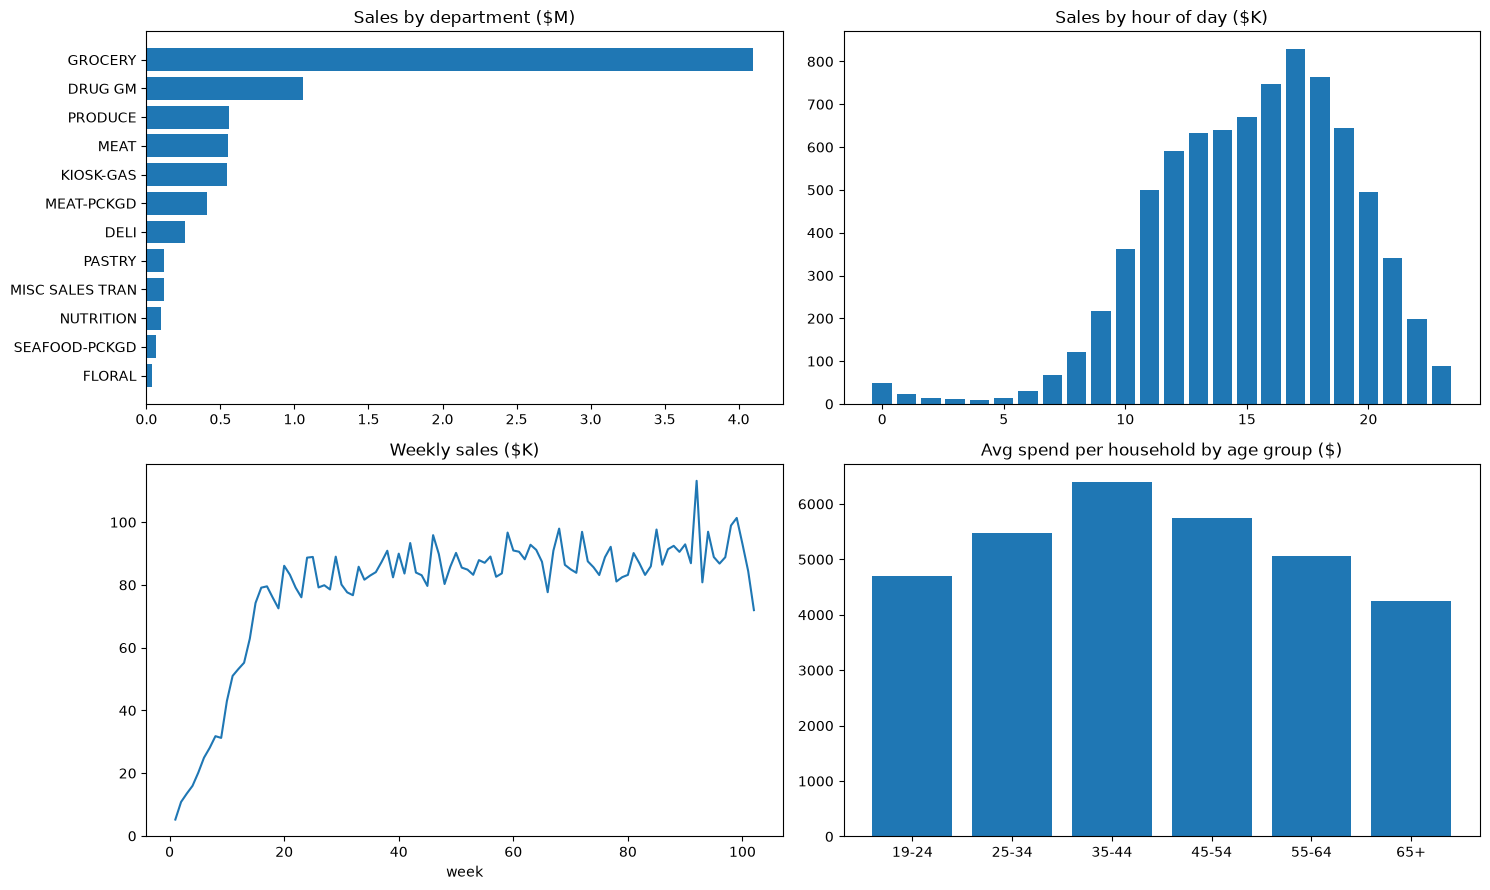

,households,spend / household,avg basket
250K+,11.0,10789.90,49.49
175-199K,11.0,8548.46,44.84
150-174K,30.0,8394.84,50.84
125-149K,38.0,7912.06,39.33
100-124K,34.0,5927.74,31.77
75-99K,96.0,5822.53,39.04
200-249K,5.0,5726.49,50.14
50-74K,192.0,5702.35,33.98
Under 15K,61.0,5559.61,26.55
25-34K,77.0,4938.07,24.96


,households,spend / household,avg basket
2 Adults Kids,187.0,6472.69,36.50
1 Adult Kids,47.0,6105.69,33.00
2 Adults No Kids,255.0,5702.32,33.64
Unknown,73.0,5230.18,28.00
Single Female,144.0,4899.47,27.72
Single Male,95.0,4830.90,28.36


,households,spend / household,avg basket
married,340.0,6136.65,35.92
unknown marital status,344.0,5268.64,28.85
single,117.0,5118.33,30.83


In [5]:
ov = stats["overview"]
display(pd.Series({"transaction lines": f"{ov['rows']:,}", "baskets": f"{ov['baskets']:,}", "households": f"{ov['households']:,}",
                   "stores": ov["stores"], "products": f"{ov['products']:,}", "weeks": f"{ov['weeks'][0]}-{ov['weeks'][1]}",
                   "total sales": f"${ov['total_sales']:,.2f}",
                   "avg basket": f"${stats['basket']['mean']:.2f} (median ${stats['basket']['median']:.2f})",
                   "avg household spend": f"${stats['household']['mean_spend']:,.2f}",
                   "private-label share": f"{stats['brand_share'].get('Private', 0):.1%}"}, name="value").to_frame())

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
dep = pd.DataFrame(stats["departments"]).head(12)
ax[0,0].barh(dep.DEPARTMENT[::-1], dep.sales[::-1] / 1e6); ax[0,0].set_title("Sales by department ($M)")
hr = pd.Series(stats["sales_by_hour"]).sort_index(key=lambda s: s.astype(int))
ax[0,1].bar(hr.index.astype(int), hr.values / 1e3); ax[0,1].set_title("Sales by hour of day ($K)")
wk = pd.Series(stats["sales_by_week"]).sort_index(key=lambda s: s.astype(int))
ax[1,0].plot(wk.index.astype(int), wk.values / 1e3); ax[1,0].set_title("Weekly sales ($K)"); ax[1,0].set_xlabel("week")
age = pd.DataFrame(stats["demographics"]["AGE_DESC"]).T.sort_index()
ax[1,1].bar(age.index, age.per_hh); ax[1,1].set_title("Avg spend per household by age group ($)")
plt.tight_layout(); plt.show()

for col in ["INCOME_DESC", "HH_COMP_DESC", "MARITAL_STATUS_CODE"]:
    display(pd.DataFrame(stats["demographics"][col]).T[["hh", "per_hh", "basket_value"]]
            .rename(columns={"hh": "households", "per_hh": "spend / household", "basket_value": "avg basket"}).round(2))

## 3. Tokenizer (Qwen3 BPE)

In [6]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")   # same vocabulary as Qwen3-8B used in notebook 5
EOS_ID  = tokenizer.convert_tokens_to_ids("<|endoftext|>")      # 151643
IM_START, IM_END = tokenizer.convert_tokens_to_ids(["<|im_start|>", "<|im_end|>"])
VOCAB_SIZE = QWEN3_VOCAB_SIZE                                   # 151,936 (> len(tokenizer) = 151,669)
print(f"base vocab {tokenizer.vocab_size:,}, with special tokens {len(tokenizer):,}, model rows {VOCAB_SIZE:,}")
print("ids:", EOS_ID, IM_START, IM_END)
print(tokenizer.tokenize("What is the average basket value at SuperMart?"))

base vocab 151,643, with special tokens 151,669, model rows 151,936
ids: 151643 151644 151645
['What', 'Ġis', 'Ġthe', 'Ġaverage', 'Ġbasket', 'Ġvalue', 'Ġat', 'ĠSuper', 'Mart', '?']


## 4. Model configuration

Same Qwen3 architecture as notebook 5 (now in `slm/model.py` so the notebook, export and tests share it).
`max_seq_len` 512 covers a full system + question + answer conversation.

In [7]:
MODEL_CONFIG = dict(vocab_size=VOCAB_SIZE, d_model=768, n_heads=12, n_kv_groups=6, n_layers=12,
                    d_ff=3072, max_seq_len=512, rope_theta=10_000.0)
BLOCK = MODEL_CONFIG["max_seq_len"]

def new_model():
    m = Qwen3Model(**MODEL_CONFIG).to(device)           # fp32 master weights; autocast does bf16/fp16 maths
    m.gradient_checkpointing = LOW_VRAM
    return m

def save_ckpt(model, path):
    torch.save({"model": model.state_dict(), "config": MODEL_CONFIG}, path)

def load_into(model, path):
    sd, _ = load_checkpoint(path)
    sd = resize_vocab(sd, VOCAB_SIZE)                   # old 151,643-row checkpoints -> 151,936
    model.load_state_dict({k: v.float() for k, v in sd.items()})
    return model

model = new_model()
print(f"parameters: {count_parameters(model)/1e6:.1f}M  | GPU memory after load: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

parameters: 339.6M  | GPU memory after load: 1.28 GB


### Shared training loop
AdamW (β=(0.9,0.95), wd 0.1 on matrices only; **8-bit** on low-VRAM GPUs - fp32 Adam states alone would need 2.7 GB), linear warm-up → cosine decay **per optimizer step**,
gradient accumulation, mixed precision, grad-clip 1.0, periodic train/val evaluation, best + final checkpoints.

In [8]:
def lr_at(step, max_steps, lr, min_lr, warmup):
    if step < warmup:
        return lr * (step + 1) / warmup
    p = min(1.0, (step - warmup) / max(1, max_steps - warmup))
    return min_lr + 0.5 * (1 + math.cos(math.pi * p)) * (lr - min_lr)

@torch.no_grad()
def estimate_loss(model, get_batch, eval_iters):
    model.eval(); out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_iters):
            with ctx:
                _, loss = model(*get_batch(split))
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train(); return out

def train_stage(name, model, get_batch, max_steps, lr, min_lr, warmup, grad_accum, eval_every, eval_iters, ckpt):
    decay   = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{"params": decay, "weight_decay": 0.1}, {"params": nodecay, "weight_decay": 0.0}]
    if LOW_VRAM and HAS_BNB:
        opt = bnb.optim.AdamW8bit(groups, lr=lr, betas=(0.9, 0.95), eps=1e-8)
    elif LOW_VRAM:   # no bitsandbytes: Adafactor keeps factored (tiny) optimizer state
        opt = torch.optim.Adafactor(groups, lr=lr)
    else:
        opt = torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.95), eps=1e-8, fused=True)
    scaler = torch.amp.GradScaler(device_type, enabled=(dtype == "float16"))
    hist, best, t0 = {"step": [], "train": [], "val": [], "lr": []}, float("inf"), time.time()
    model.train()
    for step in tqdm(range(max_steps + 1), desc=name):
        cur_lr = lr_at(step, max_steps, lr, min_lr, warmup)
        for g in opt.param_groups: g["lr"] = cur_lr
        if step % eval_every == 0 or step == max_steps:
            l = estimate_loss(model, get_batch, eval_iters)
            for k, v in [("step", step), ("train", l["train"]), ("val", l["val"]), ("lr", cur_lr)]: hist[k].append(v)
            tqdm.write(f"[{name}] step {step:>6}  train {l['train']:.4f}  val {l['val']:.4f}  "
                       f"ppl {math.exp(min(l['val'], 20)):.1f}  lr {cur_lr:.2e}  {time.time()-t0:.0f}s")
            if l["val"] < best:
                best = l["val"]; save_ckpt(model, ckpt.replace(".pt", "_best.pt"))
        if step == max_steps:
            break
        for _ in range(grad_accum):
            with ctx:
                _, loss = model(*get_batch("train"))
            scaler.scale(loss / grad_accum).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    save_ckpt(model, ckpt)
    del opt; torch.cuda.empty_cache()
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated()/1024**3:.2f} GB")
    json.dump(hist, open(ckpt.replace(".pt", "_history.json"), "w"))
    return hist

def bin_batcher(prefix, block, batch_size):
    def get(split):
        data = np.memmap(f"{prefix}_{split}.bin", dtype=np.uint32, mode="r")
        ix = np.random.randint(0, len(data) - block - 1, batch_size)
        x = torch.from_numpy(np.stack([data[i:i + block] for i in ix]).astype(np.int64))
        y = torch.from_numpy(np.stack([data[i + 1:i + 1 + block] for i in ix]).astype(np.int64))
        if device == "cuda":
            return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
        return x.to(device), y.to(device)
    return get

def write_bin(token_lists, path):
    n = sum(len(t) for t in token_lists)
    arr = np.memmap(path, dtype=np.uint32, mode="w+", shape=(n,)); i = 0
    for t in token_lists:
        arr[i:i + len(t)] = t; i += len(t)
    arr.flush(); return n

## 5. Stage A — pre-training from scratch on our supermarket transactions

No outside text: the model learns language *from our own data*. `scripts/build_dataset.py` turns every one of the
276,484 baskets in `combined_supermarket_data.csv` into one line of text (store, week/day/time, household
demographics, every item with department, brand type, size, quantity, price and discount, basket total), e.g.

```
Store 396, week 1, day 1 at 09:46. Household 1172 (age 25-34, single, income 50-74K, ...). Bought:
Body Wash (Drug Gm, national brand) x1 for $2.29; Toothpaste (Drug Gm, national brand, 6 OZ) x1 for $2.00,
saved $0.99; ... Basket total $23.41 for 9 items.
```
≈ 100M tokens; the last 5 % of baskets in time are the validation set. An `<|endoftext|>` token separates baskets.
Resumes from `checkpoints/base_retail.pt` if that already exists.

In [9]:
BASE_CKPT = "checkpoints/base_retail.pt"
RUN_STAGE_A = not os.path.exists(BASE_CKPT)
print("run stage A:", RUN_STAGE_A)

def tokenize_lines_to_bin(txt_path, bin_path, chunk=20_000):
    # stream the text file -> uint32 token file (EOS after every basket)
    n = 0
    with open(txt_path, encoding="utf-8") as f, open(bin_path, "wb") as out:
        total = sum(1 for _ in open(txt_path, encoding="utf-8"))
        buf = []
        for line in tqdm(f, total=total, desc=f"tokenizing {os.path.basename(txt_path)}"):
            buf.append(line.rstrip("\n"))
            if len(buf) == chunk:
                ids = [t + [EOS_ID] for t in tokenizer(buf, add_special_tokens=False)["input_ids"]]
                arr = np.fromiter((i for t in ids for i in t), dtype=np.uint32); arr.tofile(out); n += len(arr); buf = []
        if buf:
            ids = [t + [EOS_ID] for t in tokenizer(buf, add_special_tokens=False)["input_ids"]]
            arr = np.fromiter((i for t in ids for i in t), dtype=np.uint32); arr.tofile(out); n += len(arr)
    return n

if RUN_STAGE_A:
    for split in ["train", "val"]:
        txt, bin_ = f"data/transactions_corpus_{split}.txt", f"retail_{split}.bin"
        assert os.path.exists(txt), "run scripts/build_dataset.py (section 1) to create the basket text"
        if not os.path.exists(bin_):
            print(split, f"{tokenize_lines_to_bin(txt, bin_):,} tokens")
    P = PROFILE["A"]
    hist_a = train_stage("A:retail", model, bin_batcher("retail", P["block"], P["batch"]),
                         max_steps=P["steps"], lr=6e-4, min_lr=6e-5, warmup=300, grad_accum=P["accum"],
                         eval_every=250, eval_iters=40, ckpt=BASE_CKPT)
else:
    load_into(model, BASE_CKPT)
    hist_a = json.load(open(BASE_CKPT.replace(".pt", "_history.json")))
    print("loaded", BASE_CKPT)

model.eval()
with ctx:
    prompt = "Store 367, week 60, day 410 at 17:15. Household 718"
    ids = torch.tensor([tokenizer.encode(prompt, add_special_tokens=False)], device=device)
    print(tokenizer.decode(model.generate(ids, 80, temperature=0.8, top_k=50)[0]))
model.train()

run stage A: True


tokenizing transactions_corpus_train.txt:   0%|          | 0/262659 [00:00<?, ?it/s]

tokenizing transactions_corpus_train.txt:   8%|▊         | 20000/262659 [00:02<00:25, 9408.83it/s]

tokenizing transactions_corpus_train.txt:  15%|█▌        | 40000/262659 [00:05<00:30, 7210.19it/s]

tokenizing transactions_corpus_train.txt:  23%|██▎       | 60000/262659 [00:09<00:32, 6142.40it/s]

tokenizing transactions_corpus_train.txt:  30%|███       | 80000/262659 [00:13<00:32, 5684.91it/s]

... (4,049 outputs left out)

A:retail: 100%|█████████▉| 4000/4001 [3:52:26<00:03,  3.49s/it]

peak GPU memory: 5.52 GB


Store 367, week 60, day 410 at 17:15. Household 718 (age 45-54, married, income 25-34K, homeowner, 2 Adults Kids, 5+ people, 3+ kid(s)). Bought: Sft Drnk Sngl Srv Btl Carb (Ex (Grocery, national brand, 20 OZ) x1 for $1.11, saved $0.


Qwen3Model(
  (tok_emb): Embedding(151936, 768)
  (blocks): ModuleList(
    (0-11): 12 x TransformerBlock(
      (attention): GroupedQueryAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=384, bias=False)
        (W_value): Linear(in_features=768, out_features=384, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=False)
        (q_norm): RMSNorm()
        (k_norm): RMSNorm()
      )
      (feed_forward): SwiGLUFeedForward(
        (gate_proj): Linear(in_features=768, out_features=3072, bias=False)
        (up_proj): Linear(in_features=768, out_features=3072, bias=False)
        (down_proj): Linear(in_features=3072, out_features=768, bias=False)
      )
      (norm1): RMSNorm()
      (norm2): RMSNorm()
    )
  )
  (final_norm): RMSNorm()
  (out_head): Linear(in_features=768, out_features=151936, bias=False)
)

## 6. Stage B — domain-adaptive pre-training

Continues next-token training on the cleaned research papers, the retail glossary and the
data-insight paragraphs computed from the CSV. 10 % of every document is held out as validation.

In [10]:
tr_ids, va_ids = [], []
for r in corpus:
    ids = tokenizer.encode(r["text"], add_special_tokens=False) + [EOS_ID]
    cut = int(len(ids) * 0.9)
    tr_ids.append(ids[:cut]); va_ids.append(ids[cut:])
n_tr, n_va = write_bin(tr_ids, "domain_train.bin"), write_bin(va_ids, "domain_val.bin")
print(f"domain tokens: train {n_tr:,}  val {n_va:,}")

P = PROFILE["B"]
hist_b = train_stage("B:domain", model, bin_batcher("domain", P["block"], P["batch"]),
                     max_steps=P["steps"], lr=3e-4, min_lr=3e-5, warmup=100, grad_accum=P["accum"],
                     eval_every=100, eval_iters=20, ckpt="checkpoints/domain.pt")

domain tokens: train 177,923  val 19,793


B:domain:   0%|          | 0/801 [00:00<?, ?it/s]

B:domain:   0%|          | 0/801 [00:02<?, ?it/s]

[B:domain] step      0  train 12.7424  val 12.1569  ppl 190406.6  lr 3.00e-06  2s


B:domain:   0%|          | 1/801 [00:12<2:48:32, 12.64s/it]

B:domain:   0%|          | 2/801 [00:14<1:23:58,  6.31s/it]

... (812 outputs left out)

B:domain: 100%|█████████▉| 800/801 [22:05<00:01,  1.46s/it]

B:domain: 100%|█████████▉| 800/801 [22:05<00:01,  1.66s/it]

[B:domain] step    800  train 1.3172  val 6.6348  ppl 761.1  lr 3.00e-05  1326s


peak GPU memory: 5.52 GB


## 7. Stage C — supervised chat fine-tuning (SFT)

Each conversation is rendered in **ChatML** — exactly the format Ollama's template produces:

```
<|im_start|>system\n{system}<|im_end|>\n<|im_start|>user\n{question}<|im_end|>\n<|im_start|>assistant\n{answer}<|im_end|>
```
The loss is computed **only on the assistant answer + `<|im_end|>`** (loss mask), so the model learns to answer
and to stop. We keep training to memorise the facts (the final checkpoint is exported); validation contains
*unseen* facts and measures generalisation.

In [11]:
def encode_chat(messages, block=BLOCK):
    ids, mask = [], []
    for m in messages:
        head = tokenizer.encode(f"<|im_start|>{m['role']}\n", add_special_tokens=False)
        body = tokenizer.encode(m["content"], add_special_tokens=False) + [IM_END]
        nl   = tokenizer.encode("\n", add_special_tokens=False)
        learn = int(m["role"] == "assistant")
        ids += head + body + nl; mask += [0] * len(head) + [learn] * len(body) + [0] * len(nl)
    ids, mask = ids[:block + 1], mask[:block + 1]
    return ids, mask

def to_tensors(rows):
    X, Y, M = [], [], []
    for r in rows:
        ids, mask = encode_chat(r["messages"])
        pad = BLOCK + 1 - len(ids)
        ids, mask = ids + [EOS_ID] * pad, mask + [0] * pad
        X.append(ids[:-1]); Y.append(ids[1:]); M.append(mask[1:])
    return torch.tensor(X), torch.tensor(Y), torch.tensor(M)

lens = [len(encode_chat(r["messages"])[0]) for r in sft_tr]
print(f"conversation length: mean {np.mean(lens):.0f}, max {max(lens)} tokens (block {BLOCK})")
SFT = {"train": to_tensors(sft_tr), "val": to_tensors(sft_va)}

def sft_batcher(batch_size):
    def get(split):
        X, Y, M = SFT[split]
        ix = torch.randint(len(X), (batch_size,))
        return X[ix].to(device), Y[ix].to(device), M[ix].to(device)
    return get

P = PROFILE["C"]
hist_c = train_stage("C:sft", model, sft_batcher(P["batch"]),
                     max_steps=P["steps"], lr=1e-4, min_lr=1e-5, warmup=50, grad_accum=P["accum"],
                     eval_every=100, eval_iters=10, ckpt="checkpoints/supermart_sft.pt")
FINAL_CKPT = "checkpoints/supermart_sft.pt"

conversation length: mean 160, max 487 tokens (block 512)


C:sft:   0%|          | 0/801 [00:00<?, ?it/s]

C:sft:   0%|          | 0/801 [00:01<?, ?it/s]

[C:sft] step      0  train 2.6079  val 2.4819  ppl 12.0  lr 2.00e-06  1s


C:sft:   0%|          | 1/801 [00:22<5:04:30, 22.84s/it]

C:sft:   0%|          | 2/801 [00:24<2:18:23, 10.39s/it]

... (812 outputs left out)

C:sft: 100%|█████████▉| 800/801 [19:37<00:01,  1.40s/it]

C:sft: 100%|█████████▉| 800/801 [19:37<00:01,  1.47s/it]

[C:sft] step    800  train 0.0106  val 2.8713  ppl 17.7  lr 1.00e-05  1177s


peak GPU memory: 5.52 GB


## 8. Evaluation

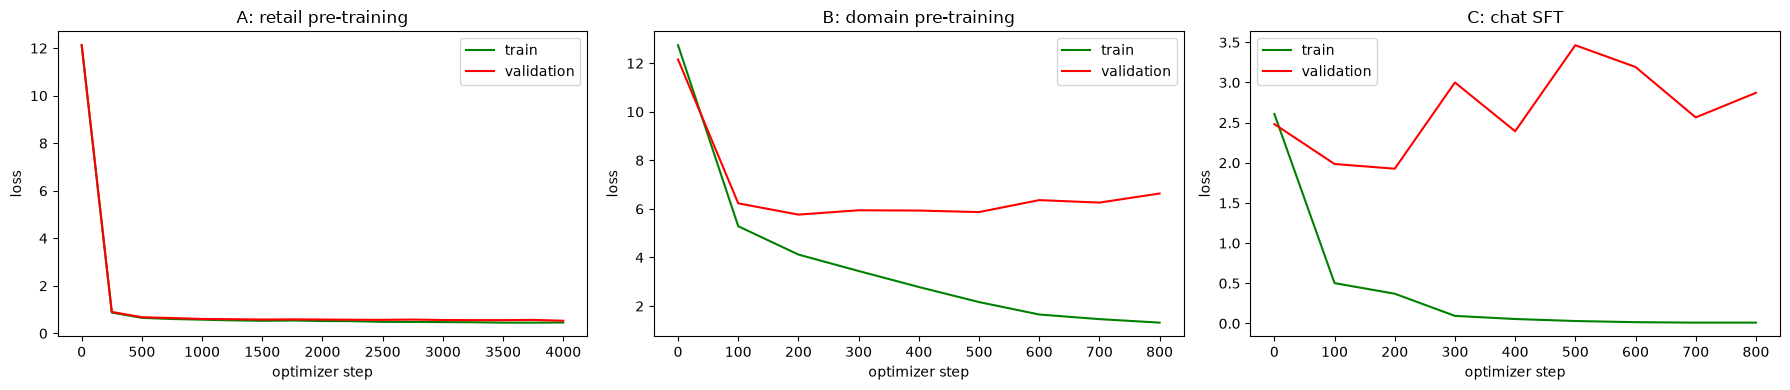

,stage,final train loss,final val loss,best val loss,val perplexity
0,A retail,0.455,0.529,0.529,1.697
1,B domain,1.317,6.635,5.766,761.139
2,C SFT,0.011,2.871,1.927,17.660


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, (n, h) in enumerate([("A: retail pre-training", hist_a), ("B: domain pre-training", hist_b), ("C: chat SFT", hist_c)]):
    ax[i].plot(h["step"], h["train"], "g", label="train"); ax[i].plot(h["step"], h["val"], "r", label="validation")
    ax[i].set_title(n); ax[i].set_xlabel("optimizer step"); ax[i].set_ylabel("loss"); ax[i].legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "stage": ["A retail", "B domain", "C SFT"],
    "final train loss": [h["train"][-1] for h in (hist_a, hist_b, hist_c)],
    "final val loss":   [h["val"][-1] for h in (hist_a, hist_b, hist_c)],
    "best val loss":    [min(h["val"]) for h in (hist_a, hist_b, hist_c)],
})
summary["val perplexity"] = np.exp(summary["final val loss"])
display(summary.round(3))

In [13]:
SYSTEM = sft_tr[0]["messages"][0]["content"]

def chat(question, max_new_tokens=200, temperature=0.0, system=SYSTEM):
    model.eval()
    prompt = f"<|im_start|>system\n{system}<|im_end|>\n<|im_start|>user\n{question}<|im_end|>\n<|im_start|>assistant\n"
    ids = torch.tensor([tokenizer.encode(prompt, add_special_tokens=False)], device=device)
    with ctx:
        out = model.generate(ids, max_new_tokens, temperature=temperature, top_p=0.9,
                             repetition_penalty=1.1, eos_token_ids={IM_END, EOS_ID})
    return tokenizer.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

import re
NUM = re.compile(r"\$?\d[\d,]*\.?\d*%?")
def fact_recall(rows, n=None):
    rows = rows if n is None else random.Random(0).sample(rows, min(n, len(rows)))
    scores = []
    for r in tqdm(rows, desc="fact recall"):
        ref = set(NUM.findall(r["messages"][2]["content"]))
        if not ref: continue
        gen = set(NUM.findall(chat(r["messages"][1]["content"])))
        scores.append(len(ref & gen) / len(ref))
    return float(np.mean(scores)), len(scores)

tr_score, n1 = fact_recall(sft_tr, 60)
va_score, n2 = fact_recall(sft_va)
print(f"numeric fact recall - seen facts (train sample n={n1}): {tr_score:.1%} | unseen facts (val n={n2}): {va_score:.1%}")

fact recall:   0%|          | 0/60 [00:00<?, ?it/s]

fact recall:   3%|▎         | 2/60 [00:01<00:45,  1.29it/s]

fact recall:   5%|▌         | 3/60 [00:02<00:40,  1.42it/s]

fact recall:   7%|▋         | 4/60 [00:03<00:50,  1.11it/s]

fact recall:   8%|▊         | 5/60 [00:05<01:14,  1.35s/it]

fact recall:  10%|█         | 6/60 [00:06<01:09,  1.29s/it]

... (84 outputs left out)

fact recall:  75%|███████▍  | 50/67 [00:38<00:13,  1.24it/s]

fact recall:  76%|███████▌  | 51/67 [00:38<00:11,  1.44it/s]

fact recall: 100%|██████████| 67/67 [00:38<00:00,  1.73it/s]

numeric fact recall - seen facts (train sample n=50): 95.3% | unseen facts (val n=41): 4.8%


In [14]:
for q in ["Who are you?",
          "Which departments generate the most sales?",
          "What is the average basket size?",
          "What time of day do customers shop the most?",
          "How does spending vary by age group?",
          "What is gross margin?",
          "Explain RFM analysis.",
          "What is buy now pay later?"]:
    print(f"Q: {q}\nA: {chat(q)}\n")

Q: Who are you?
A: I am SuperMart SLM, a small language model trained from scratch with a Qwen3-style architecture to answer questions about supermarket retail analytics - sales, products, discounts, customer demographics, margins, pricing, payments and tax.



Q: Which departments generate the most sales?
A: The top departments by sales are: 1. Grocery ($4,093,814.14, 50.8% of sales); 2. Drug Gm ($1,055,358.03, 13.1% of sales); 3. Produce ($557,452.11, 6.9% of sales); 4. Meat ($548,786.81, 6.8% of sales); 5. Kiosk-Gas ($544,222.28, 6.8% of sales).



Q: What is the average basket size?
A: The average basket value is $29.14 (median $17.07; 90th percentile $70.65). An average basket contains 9.4 line items (median 5).



Q: What time of day do customers shop the most?
A: Sales peak at 17:00-18:00 (10.3% of daily sales). The morning (6-12) brings 16.1%, afternoon (12-17) brings 40.7%, evening (17-22) brings 38.1% of sales.



Q: How does spending vary by age group?
A: By age group, average spend per household is: 35-44: $6,402.82 (194 households, avg basket $33.91); 45-54: $5,755.09 (288 households, avg basket $32.25); 25-34: $5,478.42 (142 households, avg basket $34.27); 55-64: $5,054.73 (59 households, avg basket $29.65); 19-24: $4,708.33 (46 households, avg basket $26.64); 65+: $4,241.03 (72 households, avg basket $26.71). The highest-spending segment is '35-



Q: What is gross margin?
A: Gross margin is the difference between the selling price and the cost price of goods, usually expressed as a percentage of the selling price: Gross margin % = (Sales - Cost of goods sold) / Sales x 100. A product that sells for $10 and costs $6 has a gross margin of 40%.



Q: Explain RFM analysis.
A: RFM analysis segments customers by Recency (how recently they bought), Frequency (how often they buy) and Monetary value (how much they spend). Each customer gets a score per dimension and segments such as Champions, Loyal customers or At-risk customers are derived.



Q: What is buy now pay later?
A: Dynamic pricing changes prices over time in response to demand, inventory, competition or time of day, and is common in e-commerce and fuel retail.



## 9. Convert to the standard Qwen3 layout (local only, nothing is uploaded)

Ollama cannot read a raw PyTorch `.pt`; the GGUF converter reads the standard `Qwen3ForCausalLM` folder.
Exported in float32 so it is bit-identical to the trained model (quantisation happens in the GGUF step).
`slm/export.py` maps every tensor onto `Qwen3ForCausalLM` names, folds the `sqrt(d_model)` embedding scale into
the embedding matrix and writes `config.json`, `model.safetensors`, `generation_config.json` and the tokenizer
(with a plain ChatML chat template). The check below loads it with 🤗 transformers and compares logits.

<span id="papermill-error-cell" style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">Execution using papermill encountered an exception here and stopped:</span>

In [15]:
from slm.export import export
EXPORT_DIR = "export/supermart-slm"
export(FINAL_CKPT, EXPORT_DIR, dtype="float32")
run("scripts/verify_export.py", "--ckpt", FINAL_CKPT, "--hf", EXPORT_DIR)

from transformers import AutoModelForCausalLM
hf_tok = AutoTokenizer.from_pretrained(EXPORT_DIR)
hf_model = AutoModelForCausalLM.from_pretrained(EXPORT_DIR, dtype=torch.bfloat16).to(device)
msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "Which department has the highest sales?"}]
ids = hf_tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)["input_ids"].to(device)
out = hf_model.generate(ids, max_new_tokens=120, do_sample=False)
print(hf_tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True))

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'Qwen/Qwen3-0.6B'.


'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting GET https://huggingface.co/api/models/Qwen/Qwen3-0.6B/tree/main/additional_chat_templates


Retrying in 1s [Retry 1/5].


exported 339.6M parameters -> export/supermart-slm


CalledProcessError: Command '['C:\\Users\\sahoo\\venvs\\supermart-slm\\Scripts\\python.exe', 'scripts/verify_export.py', '--ckpt', 'checkpoints/supermart_sft.pt', '--hf', 'export/supermart-slm']' returned non-zero exit status 1.

## 10. Convert to GGUF (for Ollama)

In [ ]:
del hf_model; torch.cuda.empty_cache()
run("-m", "pip", "install", "-q", "gguf")
GGUF = "ollama/supermart-slm-q8_0.gguf"
run("scripts/convert_to_gguf.py", "--hf", EXPORT_DIR, "--out", GGUF, "--outtype", "q8_0")
print(f"{GGUF}: {os.path.getsize(GGUF)/1e6:.0f} MB")

## 11. Ollama chat demo (on your laptop)

```bash
# 1. install Ollama: https://ollama.com/download
# 2. the previous cell wrote ollama/supermart-slm-q8_0.gguf next to the Modelfile
cd ollama
# 3. import and chat
ollama create supermart-slm -f Modelfile
ollama run supermart-slm
>>> Which departments generate the most sales?
```